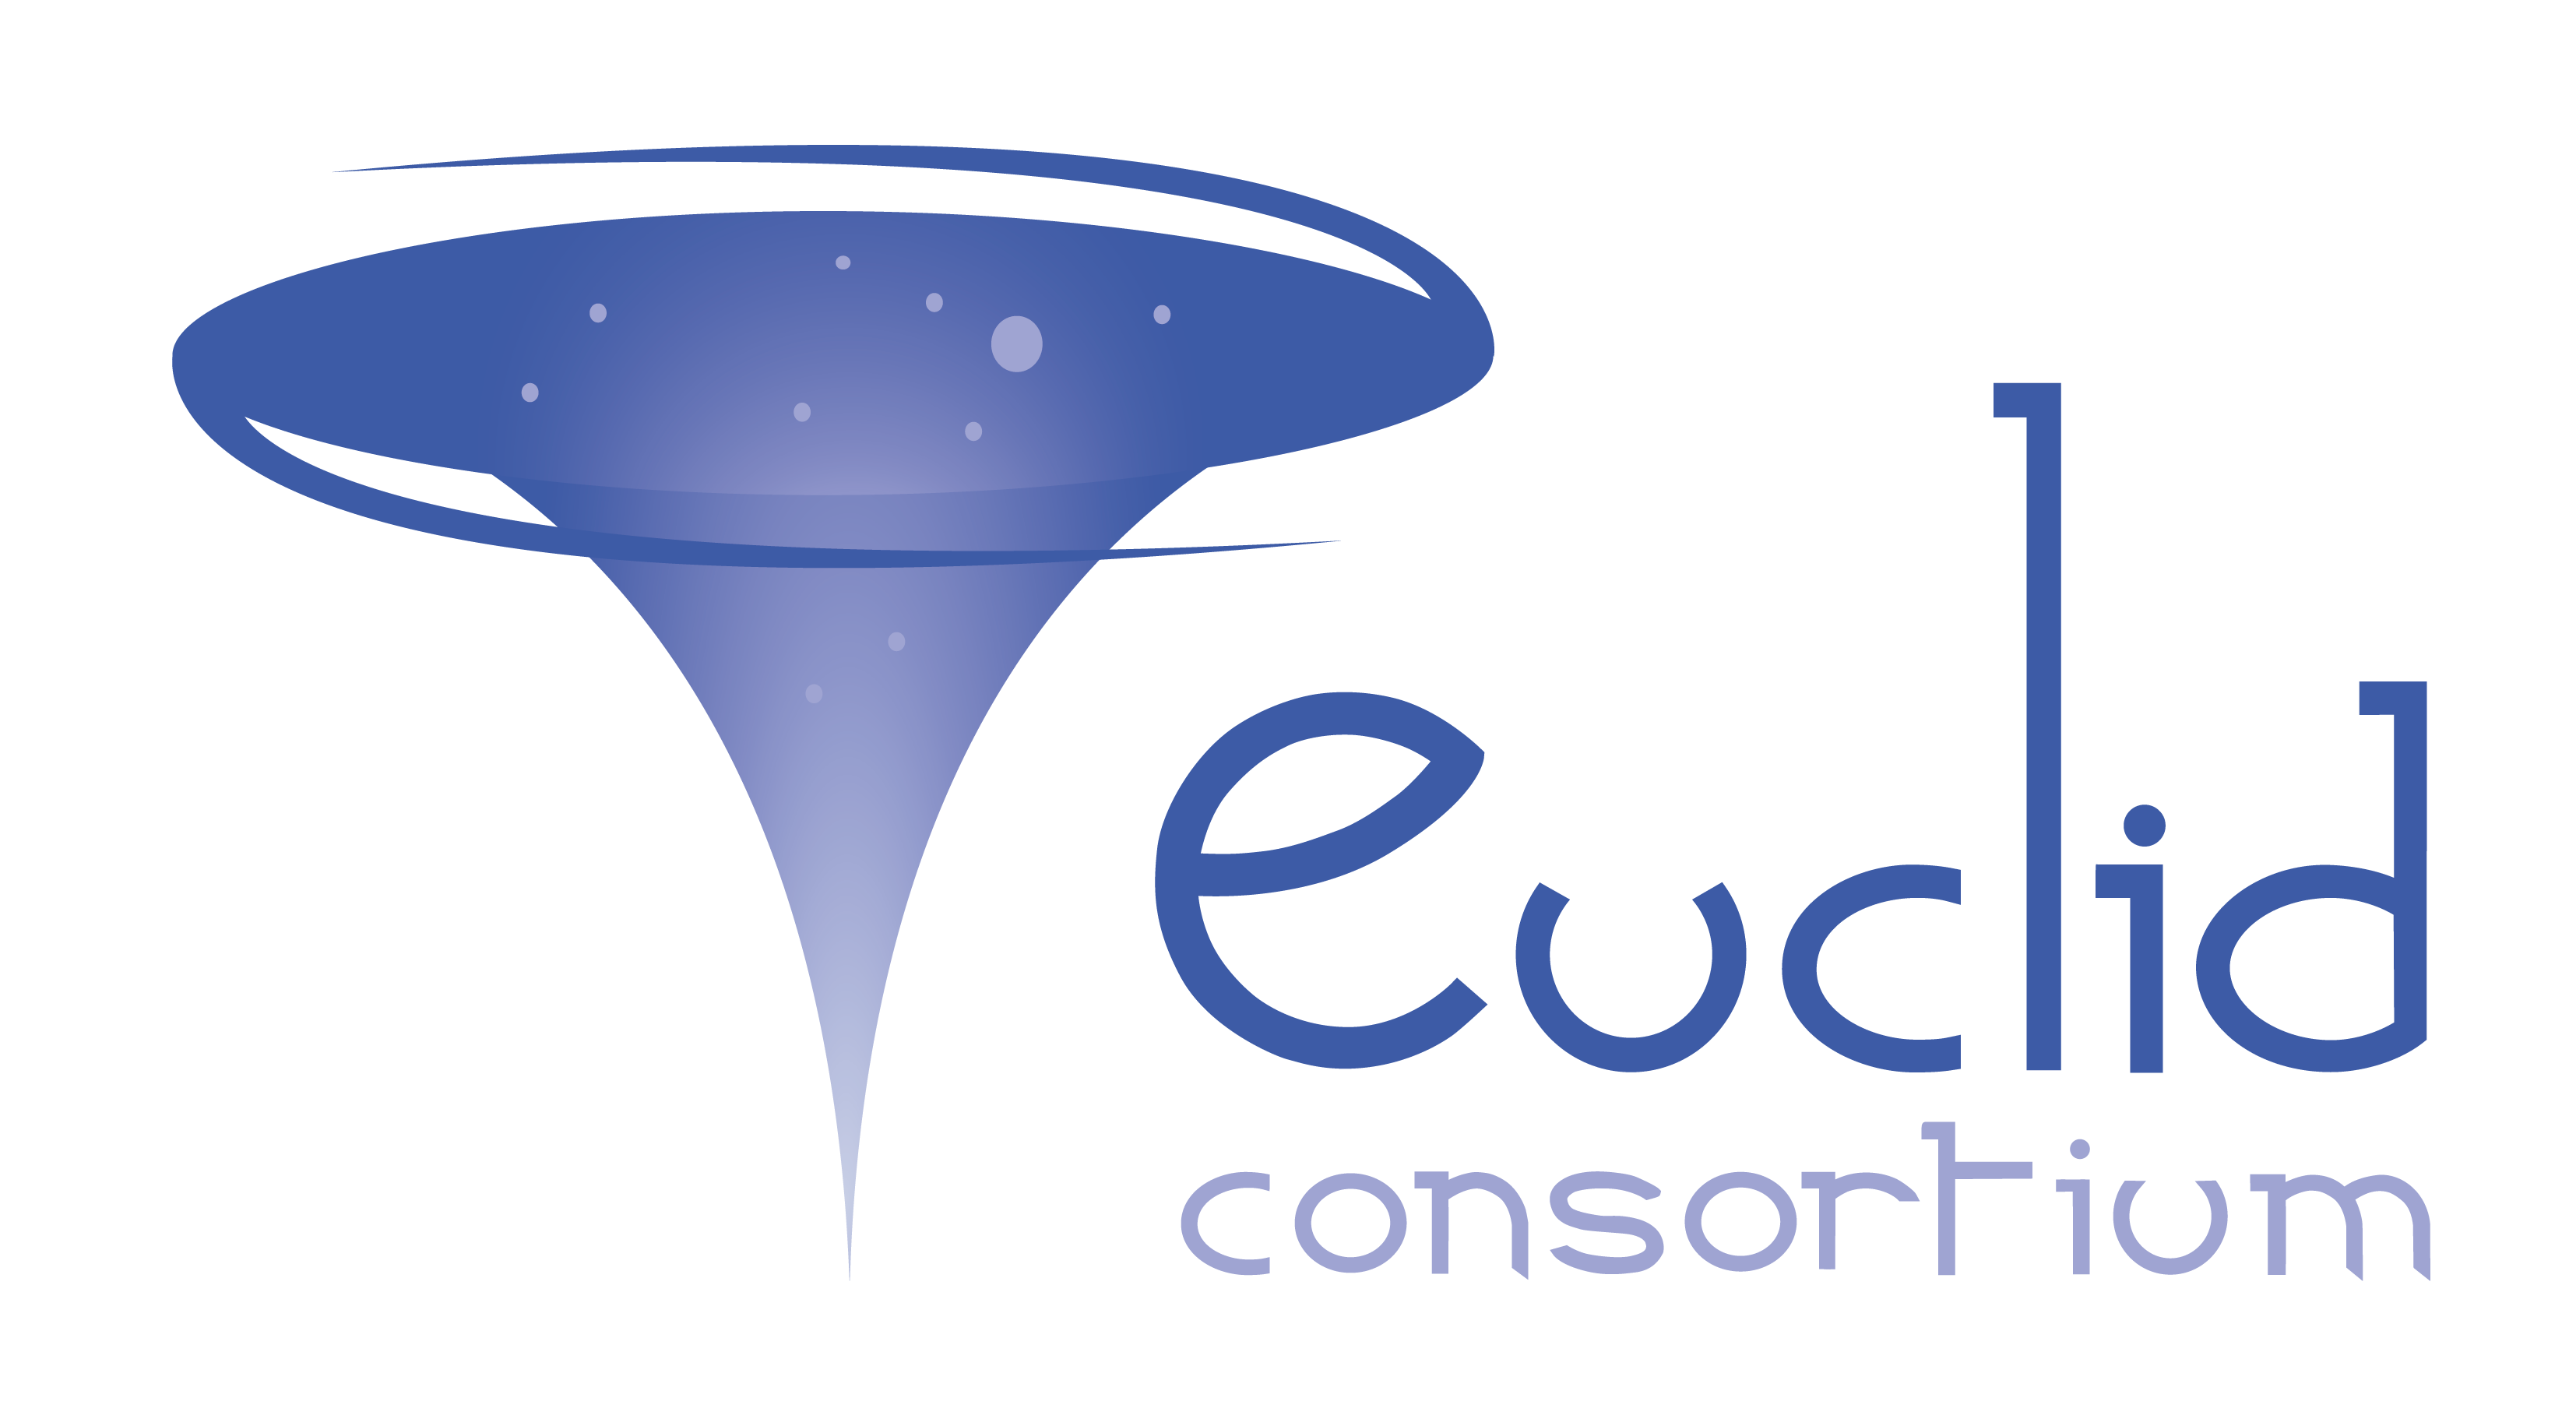
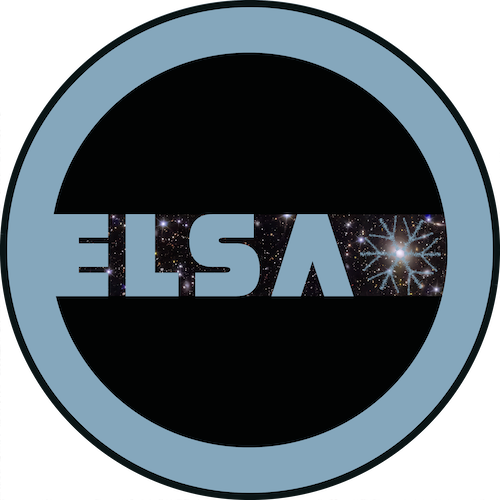


# Correcting Euclid DR1 photometry and spectra for Milky Way extinction

<br>


Copyright (c) Micol Bolzonella, 2026.

This file is subject to the terms and conditions defined in file `LICENSE.txt`, which is part of this source code package. No part of the package, including this file, may be copied, modified, propagated, or distributed except according to the terms contained in the file `LICENSE.txt`.

**Last modified:** 2026-11-12

**Notebook summary**

The light of every extragalactic source observed by Euclid crosses the dust of our Galaxy, the Milky Way (MW), which dims it and makes it redder. This notebook shows how to correct Euclid DR1 broad-band fluxes and 1D spectra for this effect, working on ESA Datalabs. It uses the PDR environment of the Euclid archive, and works both for the Wide Survey and for the Deep Fields.

In this tutorial, you will learn how to:

1. Retrieve and plot the transmission curves of the four Euclid filters: $I_E$ (from the VIS visible imager) and $Y_E$, $J_E$, $H_E$ (from the NISP near-infrared instrument)
2. Derive an average correction coefficient $C_X$ for each filter, given an extinction law (Gordon et al. 2023) and a reference spectral energy distribution (SED), here a black body
3. Select sources from the Euclid photometric catalogue through an ADQL query (the SQL-like query language of the archive), retrieving their fluxes and the Galactic reddening E(B-V) at their position (column `gal_ebv`)
4. Correct the fluxes (and magnitudes) for the MW attenuation
5. Retrieve the 1D spectrum of a source and correct it for the MW attenuation

**Euclid terms used in this notebook.** The Euclid data are produced by processing steps of the Euclid Science Ground Segment, each run by an Organisation Unit (OU). Their names appear in table and column names:

* **MER**: the step that merges the information from all the Euclid images (and external ground-based data) into the main photometric catalogue. We call it here the *photometric (MER) catalogue*.
* **SIR**: the step that extracts the 1D spectra from the NISP slitless-spectroscopy images. The spectra are taken with two grisms: the blue grism (**BGS**) and the red grism (**RGS**).
* **SPE**: the step that measures spectroscopic redshifts from the 1D spectra.
* **PHZ**: the step that determines photometric redshifts, classification, and physical properties from the fluxes.
* **EDF-N**: Euclid Deep Field North, one of the three Euclid Deep Fields. 

**Important:** fluxes in the photometric (MER) catalogue and the combined 1D spectra are **not** corrected for MW extinction. The photometric-redshift pipeline (OU-PHZ) applies its own correction internally, so the PHZ outputs do not need further correction.


**Useful links:**

* [Euclid DR1 Help pages](https://euclid.dataspace.esa.int/community/help-pages/EDS_Portal_Help.html)
* [DR1 data release homepage](https://www.cosmos.esa.int/web/euclid/euclid-dr1)
* [Euclid DR1 data product description (Data Model)](https://euclid.esac.esa.int/dr/dr1/dpdd/)
* [Euclid Astroquery documentation](https://astroquery.readthedocs.io/en/latest/esa/euclid/euclid.html)
* [dust_extinction package](https://dust-extinction.readthedocs.io/en/stable/index.html): [Gordon 2024, JOSS, 9(100), 7023](https://ui.adsabs.harvard.edu/abs/2024JOSS....9.7023G)
* [NISP official passbands](https://euclid.esac.esa.int/msp/refdata/nisp/NISP-PHOTO-PASSBANDS-V1)
* [SVO Filter Profile Service](http://svo2.cab.inta-csic.es/theory/fps/index.php)
* [SVO Filter Profile Service - Euclid bands](http://svo2.cab.inta-csic.es/theory/fps/index.php?mode=browse&gname=Euclid)


**Related ADQL queries:**

In the example query below, the photometry and the Galactic E(B-V) are selected for a tile (one of the sky areas in which the photometric catalogue is produced) of the EDF-N.

```sql
SELECT 
mer.object_id, mer.right_ascension, mer.declination, mer.tile_index,
mer.gal_ebv, 
mer.flux_vis_sersic, mer.fluxerr_vis_sersic,
mer.flux_y_sersic, mer.fluxerr_y_sersic,
mer.flux_j_sersic, mer.fluxerr_j_sersic,
mer.flux_h_sersic, mer.fluxerr_h_sersic
FROM catalogue.mer_catalogue_deep_survey AS mer
WHERE mer.tile_index=101834632 -- tiles starting with 101 are for the deep, 102 are for the wide
AND mer.spurious_flag=0
```

and in the following one the location of the spectra files is retrieved together with `gal_ebv` and the spectroscopic (SPE) redshift:

```sql
SELECT spec.source_id, spec.datalabs_path, spec.file_name, spec.hdu_index,
mer.gal_ebv, spe.spe_z, combined.lambda_range
FROM dr1.spectra_source AS spec
JOIN catalogue.mer_catalogue_deep_survey AS mer ON spec.source_id = mer.object_id
JOIN catalogue.spectro_z_spe_galaxy_candidates_deep AS spe 
  ON spec.source_id = spe.object_id AND spe.spe_rank = 0
JOIN dr1.combined_spectra AS combined 
  ON spec.combined_spectra_fk = combined.combined_spectra_oid
WHERE mer.object_id = 2700053415663577514
```

In the notebook all the table names are defined in a single cell (see "Tables used in the queries" below). To work on the Wide Survey, set `survey = 'wide'` in that cell (the description of the available tables is at https://euclid.dataspace.esa.int/internal-archive-help/Data_products__catalogues.html).


**Running the notebook:** 

* You can modify this notebook or copy it to a different location. The original notebook is located at https://github.com/esa/euclid-contributed-jupyter-notebooks/.
* The notebook is self-contained: all the functions are defined in the notebook itself. They are listed in the section "Useful functions", and `help(function_name)` prints their documentation.
* You need to log in to the archive only once, at the beginning (Sections 1 and 2 do not need the login). If the login expires, the queries log in again automatically.
* The notebook is intended to be run using the **EUCLID-TOOLS kernel**, which includes the package `dust_extinction` used for the extinction law.
* The filter transmission curves are downloaded from the SVO Filter Profile Service. If the service cannot be reached, they are read from local files (see Section 1).


**Version:**

* v1.0 (2026-11-08): first version for the DR1 notebook pack
***


In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator, FixedLocator, FuncFormatter
from astropy.table import Table
import astropy.units as u
from astropy.io import fits
from astropy.modeling.physical_models import BlackBody
from astroquery import log as aq_log
from astroquery.esa.euclid.core import EuclidClass
from astroquery.svo_fps import SvoFps
import time, datetime
import getpass
import warnings
from astropy.units import UnitsWarning
import os
import re
import io
import contextlib
import logging
from IPython.display import display
from dust_extinction.parameter_averages import G23

warnings.filterwarnings('ignore', category=UnitsWarning)

In [2]:
#make a folder in your workspace for the output files
output_folder = '/media/user/example_notebook_outputs/'
if not os.path.exists(output_folder):
    os.makedirs(output_folder)

## Choosing the environment and logging in

Log in **once**, with the next cell. It is possible to login using many different options - see the [Euclid.login](https://astroquery.readthedocs.io/en/latest/api/astroquery.esa.euclid.EuclidClass.html#astroquery.esa.euclid.EuclidClass.login) method for details. As for the archive website, for safety reasons the login expires after a period of time. If this happens during the notebook, the queries detect it (HTTP 401 / 403 errors), log in again automatically with the credentials entered here (kept only in the memory of the current session) and repeat the query once; any other error is shown as it is. To log in again by hand, re-run the next cell.

Sections 1 and 2 do not need the login, so they can be run also outside Datalabs.

In [3]:
Euclid = EuclidClass(environment='PDR')
user = input('Enter your user name: ')
password = getpass.getpass(prompt='Enter your password: ')
Euclid.login(user=user, password=password, verbose=False)

relogin = lambda: Euclid.login(user=user, password=password, verbose=False)    # used only if the login expires
QUERY_OPTIONS = dict(relogin=relogin)

Enter your user name:  skruk
Enter your password:  ········


INFO: Login to Euclid TAP server: eas.esac.esa.int:443/tap-server/tap/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid data service: eas.esac.esa.int:443/sas-dd/tap-server/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid cutout service: eas.esac.esa.int:443/sas-cutout/tap-server/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid sia service: eas.esac.esa.int:443/sas-sia/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]


## Tables used in the queries

All the archive tables used in the notebook are defined in the next cell, so that the queries do not need to be modified if a table is renamed or if you want to work on a different survey.

* `schema_cat`, `schema_dr1`: the schemas, i.e. the groups of tables in the archive. They may change between data releases (e.g. from `catalogue` to `dr1.catalogue`): in that case only these two lines need to be updated.
* `survey`: `'deep'` for the Deep Fields or `'wide'` for the Wide Survey (see Section 3). It selects the corresponding photometric and spectroscopic-redshift catalogues.

The tables are:

| Variable | Content |
|---|---|
| `table_mer` | Photometric (MER) catalogue: positions, fluxes and `gal_ebv` |
| `table_spe` | Spectroscopic (SPE) redshifts; `spe_rank = 0` is the most probable solution |
| `table_qual` | Quality information on the spectra |
| `table_source` | Location (path, file name, extension) of the files with the 1D spectra |
| `table_comb` | Properties of the combined spectra, including the grism (BGS or RGS) |


In [4]:
# schemas of the archive (they may change between releases, e.g. 'catalogue' -> 'dr1.catalogue')
schema_cat = 'dr1'   # catalogues (MER, SPE)
schema_dr1 = 'dr1'         # spectra tables

survey = 'deep'            # 'deep' for the Deep Fields, 'wide' for the Wide Survey

# photometric (MER) catalogue: fluxes and gal_ebv
table_mer    = f'{schema_cat}.mer_catalogue_{survey}_survey'
# spectroscopic redshifts (SPE) and their quality
table_spe    = f'{schema_cat}.spectro_z_spe_galaxy_candidates_{survey}'
table_qual   = f'{schema_cat}.spectro_z_spe_quality_{survey}'
# location of the 1D spectra files, and grism of each spectrum
table_source = f'{schema_dr1}.spectra_source'
table_comb   = f'{schema_dr1}.combined_spectra'

print(table_mer, table_spe, table_qual, table_source, table_comb, sep='\n')

dr1.mer_catalogue_deep_survey
dr1.spectro_z_spe_galaxy_candidates_deep
dr1.spectro_z_spe_quality_deep
dr1.spectra_source
dr1.combined_spectra


## Useful functions

The functions used in the notebook are listed below. The general ones are defined in the next cell, the others in the section where they are first needed. To read the full documentation of a function (input parameters, their types and the output), run `help(function_name)`.

| Function | Defined in | What it does |
|---|---|---|
| `get_query_results` | this section | Launches an ADQL query on the archive and returns the result as a table |
| `is_auth_error` | this section | Tells whether an archive error is due to a missing or expired login |
| `call_with_relogin` | this section | Calls an archive function; only if the login has expired, logs in again and retries once |
| `lambda_eff` | this section | Effective wavelength of a filter |
| `compute_C` | this section | Correction coefficient $C_X = A_X/E(B-V)$ for a filter, given an extinction law and an SED |
| `flux_to_mag` | this section | Converts fluxes in $\mu$Jy to AB magnitudes |
| `set_ticks` | this section | Common style of the plot axes |
| `bb_flam` | Section 2 | Black-body SED $F_\lambda$ on a wavelength grid |
| `plot_nonlinearity` | Section 2 | Illustrates why $A_X$ is not exactly proportional to E(B-V) |
| `correct_fluxes` | Section 4 | Adds the MW-corrected fluxes and the attenuation to a catalogue |

In [5]:
def get_query_results(query, name='query', n_rows=3, relogin=None):
    """
    Launch an asynchronous ADQL query on the Euclid archive, print the runtime
    and display the first rows of the result.

    It requires the archive object `Euclid`, already logged in (see the login cell).
    A newline is added at the end of the query, so that a '--' comment on its last
    line cannot comment out what the archive appends to the query.

    Parameters
    ----------
    query : str
        The ADQL query.
    name : str, optional
        Name of the job as it will appear in the archive (default is 'query').
    n_rows : int, optional
        Number of rows to display; 0 to display none (default is 3).
    relogin : callable, optional
        Function without arguments that logs in again, used only if the login
        has expired (default is None: errors are never retried).

    Returns
    -------
    astropy.table.Table
        The result of the query.
    """
    start = time.time()
    job = call_with_relogin(Euclid.launch_job_async, query.rstrip() + '\n', verbose=False, name=name,
                            relogin=relogin)
    res = call_with_relogin(job.get_results, relogin=relogin)
    print(f'* Output table contains {len(res):,} rows')
    print(f'* Total runtime: {time.time() - start:3.1f} seconds')
    if n_rows:
        print(f'* Displaying first {n_rows} rows: ')
        display(res[0:n_rows])
    return res


# Texts of the archive errors that mean "not logged in / session expired". The last one is the
# message logged by Euclid.launch_job_async for an expired login: the archive gives no reason
# for the HTTP error, so the message ends with "HTTP error:" followed by nothing.
AUTH_ERROR_PATTERNS = (r'Error\s+40[13]\b', r'unauthori[sz]ed', r'not\s+authenticated', r'authentication',
                       r'not\s+logged', r'login\s+required', r'session\s+(has\s+)?expired',
                       r'credentials\s+expiration', r'HTTP\s+error:\s*$')


def is_auth_error(error):
    """
    Tell whether an archive error is due to a missing or expired login.

    Parameters
    ----------
    error : Exception or str
        Exception raised by an astroquery call, or the error message logged
        by astroquery.

    Returns
    -------
    bool
        True for HTTP 401 / 403 errors and for messages about authentication
        (see AUTH_ERROR_PATTERNS).
    """
    status = getattr(getattr(error, 'response', None), 'status_code', None)
    if status in (401, 403):
        return True
    return any(re.search(p, str(error), re.IGNORECASE | re.MULTILINE) for p in AUTH_ERROR_PATTERNS)


def call_with_relogin(func, *args, relogin=None, **kwargs):
    """
    Call an archive function; only if the login has expired, log in again and
    repeat the call once.

    The Euclid archive functions of astroquery do not always raise an exception
    when a request fails: some of them (e.g. launch_job_async) log the error and
    return None. Both cases are detected: errors raised, and errors logged by
    astroquery during the call. The long HTML error page that astroquery prints
    for an expired login is hidden.

    Parameters
    ----------
    func : callable
        The archive function to call, e.g. Euclid.launch_job_async or
        Euclid.load_table.
    *args, **kwargs
        Arguments passed to `func`.
    relogin : callable, optional
        Function without arguments that logs in again (the `relogin` defined in
        the login cell). If None, errors are never retried.

    Returns
    -------
    object
        Whatever `func` returns.

    Raises
    ------
    RuntimeError
        If the request fails for any other reason than an expired login, or if
        it still fails after logging in again.
    """
    for attempt in (1, 2):
        error, printed = None, io.StringIO()
        with aq_log.log_to_list() as records, contextlib.redirect_stdout(printed):
            try:
                result = func(*args, **kwargs)
            except Exception as err:
                result, error = None, err
        messages = [r.getMessage() for r in records if r.levelno >= logging.ERROR]
        if error is None and (result is not None or not messages):
            print(printed.getvalue(), end='')
            return result
        reason = error if error is not None else messages[-1]
        if attempt == 1 and relogin is not None and is_auth_error(reason):
            print('⚠️ The login has expired: logging in again and repeating the request...')
            relogin()
            continue
        print(printed.getvalue(), end='')
        raise RuntimeError(f'The archive request failed: {str(reason)[:500]}')


def lambda_eff(lam, trans):
    """
    Compute the effective wavelength of a filter for a photon-counting device,
    i.e. the mean wavelength weighted by R = T * lambda.

    Parameters
    ----------
    lam : numpy.ndarray
        Wavelength grid in Angstrom.
    trans : numpy.ndarray
        Filter transmission T(lambda) on the same grid.

    Returns
    -------
    float
        The effective wavelength in Angstrom.
    """
    R = trans * lam
    return np.trapezoid(R * lam, lam) / np.trapezoid(R, lam)


def compute_C(lam, trans, sed_flam, ext_model, ebv_ref=0.01):
    """
    Compute the MW extinction coefficient C_X = A_X / E(B-V) for a filter X,
    defined by m_intrinsic = m_observed - C_X * E(B-V).

        C_X = -2.5 / EBV * log10( int R F 10^(-0.4 k EBV) dl / int R F dl )

    with R = T * lambda (photon counter), k(lambda) = A(lambda)/E(B-V) and
    F the intrinsic SED.

    Parameters
    ----------
    lam : numpy.ndarray
        Wavelength grid in Angstrom (usually the grid of the filter).
    trans : numpy.ndarray
        Filter transmission T(lambda) on the same grid.
    sed_flam : numpy.ndarray
        Intrinsic SED F_lambda on the same grid (any normalisation).
    ext_model : dust_extinction model
        The extinction law, e.g. G23(Rv=3.1).
    ebv_ref : float, optional
        E(B-V) at which the integral is computed; C_X is exact at this value
        (default is 0.01, see the discussion on the non-linearity in Section 2).

    Returns
    -------
    float
        The coefficient C_X.
    """
    R = trans * lam
    att = ext_model.extinguish(lam * u.AA, Ebv=ebv_ref)   # = 10^(-0.4 k EBV)
    ratio = np.trapezoid(R * sed_flam * att, lam) / np.trapezoid(R * sed_flam, lam)
    return -2.5 * np.log10(ratio) / ebv_ref


def flux_to_mag(flux_ujy):
    """
    Convert fluxes in microJansky to AB magnitudes: m = -2.5 log10(F) + 23.9.

    Parameters
    ----------
    flux_ujy : array_like
        Fluxes in microJansky.

    Returns
    -------
    numpy.ndarray
        AB magnitudes; NaN where the flux is zero or negative.
    """
    flux = np.asarray(flux_ujy, dtype=float)
    with np.errstate(divide='ignore', invalid='ignore'):
        return np.where(flux > 0, -2.5 * np.log10(flux) + 23.9, np.nan)


def set_ticks(ax, labelsize=10):
    """
    Apply the common tick style of the plots: ticks pointing inwards, on all
    four sides of the axes.

    Parameters
    ----------
    ax : matplotlib.axes.Axes
        The axes to modify.
    labelsize : int, optional
        Font size of the tick labels (default is 10).

    Returns
    -------
    None
    """
    ax.tick_params(axis='both', which='major', direction='in', length=5, labelsize=labelsize)
    ax.tick_params(axis='both', which='minor', direction='in', length=2)
    ax.xaxis.set_ticks_position('both')
    ax.yaxis.set_ticks_position('both')


For example:

In [6]:
help(compute_C)

Help on function compute_C in module __main__:

compute_C(lam, trans, sed_flam, ext_model, ebv_ref=0.01)
    Compute the MW extinction coefficient C_X = A_X / E(B-V) for a filter X,
    defined by m_intrinsic = m_observed - C_X * E(B-V).

        C_X = -2.5 / EBV * log10( int R F 10^(-0.4 k EBV) dl / int R F dl )

    with R = T * lambda (photon counter), k(lambda) = A(lambda)/E(B-V) and
    F the intrinsic SED.

    Parameters
    ----------
    lam : numpy.ndarray
        Wavelength grid in Angstrom (usually the grid of the filter).
    trans : numpy.ndarray
        Filter transmission T(lambda) on the same grid.
    sed_flam : numpy.ndarray
        Intrinsic SED F_lambda on the same grid (any normalisation).
    ext_model : dust_extinction model
        The extinction law, e.g. G23(Rv=3.1).
    ebv_ref : float, optional
        E(B-V) at which the integral is computed; C_X is exact at this value
        (default is 0.01, see the discussion on the non-linearity in Section 2).

    Re

## 1. Euclid filters

The transmission curves should include all the components of the system: for a space telescope Filter + Optics + Mirror + Detector.

By default the curves are downloaded from the SVO Filter Profile Service with `astroquery.svo_fps`. If the service cannot be reached, or if you set `filter_source = 'local'`, they are read from the local files listed in `local_filter_files` (two columns: wavelength in Angstrom and transmission).

**Filters' definitions**

* $T$ = the original tabulated transmission function
* $R = T\times \lambda$ = the modified transmission function to be used in the case of photon counter devices

For a photon counting device the AB magnitude is defined as ([Fukugita 1995](https://ui.adsabs.harvard.edu/abs/1995PASP..107..945F/abstract), [Bessell 2005](https://ui.adsabs.harvard.edu/abs/2005ARA%26A..43..293B/abstract)):

$$m_{AB} = -2.5 \log \frac{1}{c}\, \frac{\int f_{\lambda}\, R_\lambda\, d\lambda}{\int R_\lambda / \lambda^2\, d\lambda} - 48.6$$

In [7]:
# source of each transmission curve: 'svo' (SVO Filter Profile Service) or 'local' (file in local_filter_files)
filter_source = {
    'VIS': 'svo',
    'Y':   'local',
    'J':   'local',
    'H':   'local',
}

# Band name : (SVO filter ID, label for plots, MER flux column, MER flux error column)
euclid_filters = {
    'VIS': ('Euclid/VIS.vis', r'$I_{\rm E}$', 'flux_vis_sersic', 'fluxerr_vis_sersic'),
    'Y':   ('Euclid/NISP.Y',  r'$Y_{\rm E}$', 'flux_y_sersic',   'fluxerr_y_sersic'),
    'J':   ('Euclid/NISP.J',  r'$J_{\rm E}$', 'flux_j_sersic',   'fluxerr_j_sersic'),
    'H':   ('Euclid/NISP.H',  r'$H_{\rm E}$', 'flux_h_sersic',   'fluxerr_h_sersic'),
}

# used for the bands with source 'local', or if SVO cannot be reached
local_filter_files = {
    'VIS': 'VIS.dat',
    'Y':   'NISP.Y.ESA.dat',
    'J':   'NISP.J.ESA.dat',
    'H':   'NISP.H.ESA.dat',
}

In [8]:
filters = {}  # band : astropy Table with columns 'lambda' [A] and 'T'

for band, (svo_id, *_ ) in euclid_filters.items():
    if filter_source[band] == 'svo':
        try:
            data = SvoFps.get_transmission_data(svo_id, timeout=15)
            filters[band] = Table([np.asarray(data['Wavelength'], dtype=float),
                                   np.asarray(data['Transmission'], dtype=float)],
                                  names=['lambda', 'T'])
            print(f'{band:4s} <- SVO {svo_id}: {len(data)} points')
            continue
        except Exception as err:
            print(f'⚠️ {band}: SVO cannot be reached ({type(err).__name__}): reading the local file')
    file = local_filter_files[band]
    df = pd.read_csv(file, comment='#', sep=r'\s+', header=None, usecols=[0, 1], names=['lambda', 'T'])
    filters[band] = Table.from_pandas(df)
    print(f'{band:4s} <- {file}: {len(df)} points')

if not filters:
    for band, file in local_filter_files.items():
        df = pd.read_csv(file, comment='#', sep=r'\s+', header=None, usecols=[0, 1], names=['lambda', 'T'])
        filters[band] = Table.from_pandas(df)
        print(f'{band:4s} <- {file}: {len(df)} points')

leff = {band: lambda_eff(np.asarray(f['lambda']), np.asarray(f['T'])) for band, f in filters.items()}
for band in filters:
    print(f'{band:4s}  lambda_eff = {leff[band]:9.1f} A')

VIS  <- SVO Euclid/VIS.vis: 551 points
Y    <- NISP.Y.ESA.dat: 341 points
J    <- NISP.J.ESA.dat: 691 points
H    <- NISP.H.ESA.dat: 741 points
VIS   lambda_eff =    7334.4 A
Y     lambda_eff =   10866.2 A
J     lambda_eff =   13766.7 A
H     lambda_eff =   17825.2 A


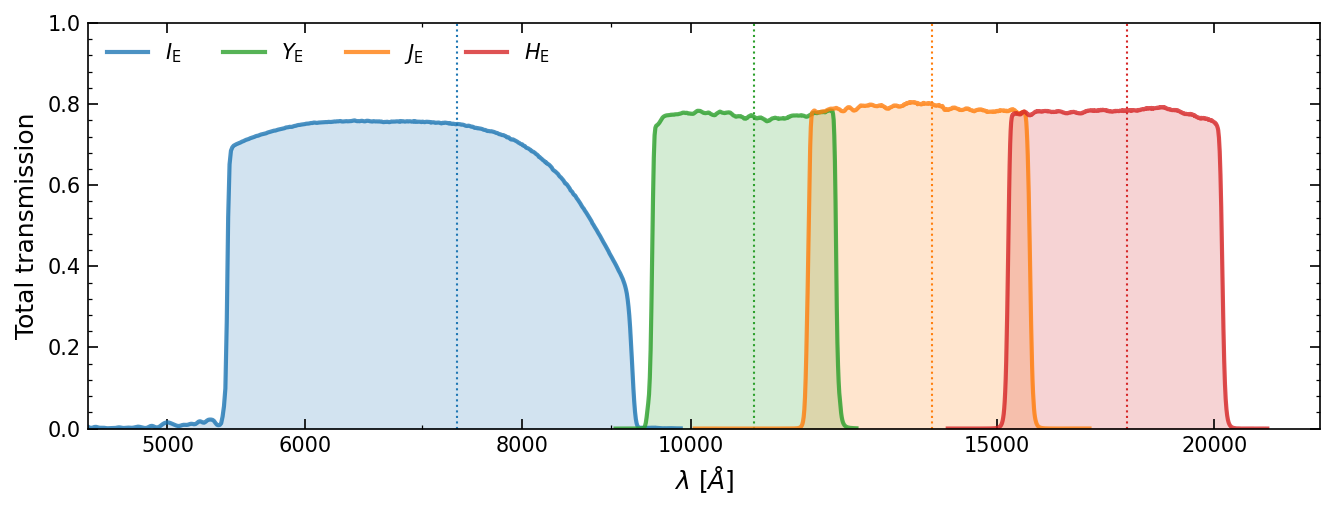

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.5), dpi=150, tight_layout=True)
colors = ['tab:blue', 'tab:green', 'tab:orange', 'tab:red']   # one per band, from blue to red

for (band, filt), col in zip(filters.items(), colors):
    label = euclid_filters[band][1]
    ax.plot(filt['lambda'], filt['T'], color=col, lw=2, alpha=0.8, label=label)
    ax.fill_between(filt['lambda'], filt['T'], 0., color=col, alpha=0.2)
    ax.axvline(leff[band], color=col, ls=':', lw=1)

ax.set_xscale('log')
major_locations = [5000, 6000, 8000, 10000, 15000, 20000, 25000]
ax.xaxis.set_major_locator(FixedLocator(major_locations))
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{int(x)}'))
ax.xaxis.set_minor_formatter(FuncFormatter(lambda x, pos: ''))
ax.yaxis.set_minor_locator(AutoMinorLocator(5))
set_ticks(ax)
ax.set_xlim(4500, 23000)
ax.set_ylim(0, 1)
ax.set_xlabel(r'$\lambda\ [\AA]$', fontsize=12)
ax.set_ylabel('Total transmission', fontsize=12)
ax.legend(fontsize=10, ncol=4, loc='upper left', frameon=False)
plt.savefig(output_folder + 'Euclid_filters.png', bbox_inches='tight', dpi=200)
plt.show()

## 2. Average MW extinction correction in the Euclid filters

The ingredients to recover the magnitude attenuation due to the MW dust are:

1. the filters transmission functions $R_X(\lambda) = T_X(\lambda) \times \lambda$ (see Section 1);
1. the E(B-V) value at the position of the source: it is available in the photometric (MER) catalogue (column `gal_ebv`), derived from the Planck map HFI_CompMap_ThermalDustModel_2048_R1.20.fits of the release version R1.20 of [Planck 2013](https://ui.adsabs.harvard.edu/abs/2014A%26A...571A..11P/abstract) (see Section 3);
1. the MW extinction curve: we adopt [Gordon et al. 2023, ApJ 950, 86](https://ui.adsabs.harvard.edu/abs/2023ApJ...950...86G/abstract) (G23) with $R_V=3.1$, available in the [dust_extinction](https://dust-extinction.readthedocs.io/en/stable/index.html) package;
1. a reference SED: for a correct computation the SED should be the one of the object (this is done in the photometric-redshift pipeline, OU-PHZ, see [Galametz et al. 2017](https://ui.adsabs.harvard.edu/abs/2017A%26A...598A..20G/abstract)), but to simplify the computation we assume a black body (by default with $T = 5700$ K, roughly a solar-type star).

**Definitions**

General relations as a function of $\lambda$ are:
* $R_V = A_V/E(B-V)$
* $k(\lambda) = A(\lambda)/E(B-V) = R_V \times A(\lambda)/A_V$
* $A(\lambda) = k(\lambda) \times E(B-V)$

For monochromatic fluxes (e.g. a spectrum) we have
$$F_{i}(\lambda) = F_{o}(\lambda)\times 10^{0.4\, A(\lambda)} = F_{o}(\lambda)\times 10^{0.4\, k(\lambda) \, E(B-V)}.$$

For a broad-band filter $X$ the quantities $A_X = C_X\times E(B-V)$ are needed to transform observed (o) to intrinsic (i) magnitudes (see also Eq. 10 in [Laigle et al. 2016](https://ui.adsabs.harvard.edu/abs/2016ApJS..224...24L/abstract)):
$$m_{X,i} = m_{X,o} - C_X\times E(B-V) \qquad \Longleftrightarrow \qquad F_{X,i} = F_{X,o}\times 10^{0.4\, C_X\, E(B-V)}$$

where $C_X$ is the integrated quantity in the filter $X$:
$$ C_X = -\frac{2.5}{E(B-V)}\log\frac{\int R_X(\lambda)\, F(\lambda)\, 10^{-0.4\,k(\lambda)\,E(B-V)}  \, d\lambda}{\int R_X(\lambda)\, F(\lambda)\, d\lambda} $$

and $F(\lambda)$ is the intrinsic SED.

### Extinction law

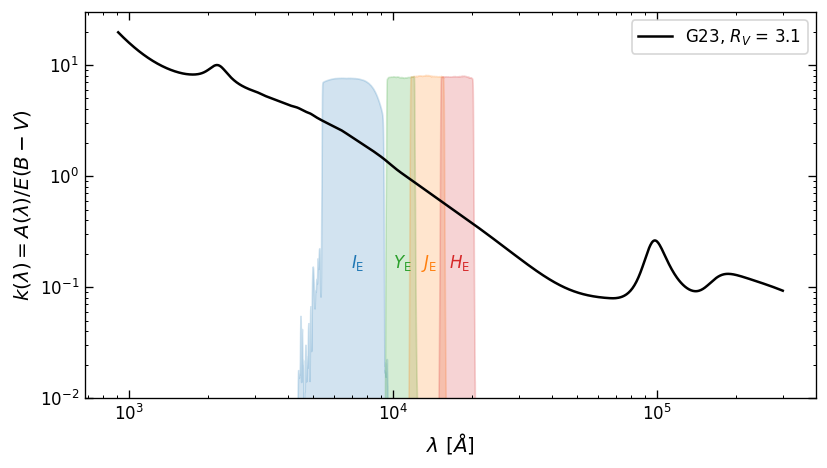

In [10]:
RV = 3.1
ext = G23(Rv=RV)   # G23 is defined between 0.0912 and 32 micron

lam_plot = np.logspace(np.log10(912.), np.log10(3.e5), 1000) * u.AA
k_lambda = ext(lam_plot) * RV     # k(lambda) = A(lambda)/E(B-V)

fig, ax = plt.subplots(figsize=(7, 4), dpi=120, tight_layout=True)
ax.plot(lam_plot, k_lambda, 'k', label=f'G23, $R_V$ = {RV}')
for (band, filt), col in zip(filters.items(), colors):
    ax.fill_between(filt['lambda'], 10 * filt['T'], 0., color=col, alpha=0.2)
    ax.text(leff[band], 0.15, euclid_filters[band][1], color=col, ha='center')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(0.01, 30)
ax.set_xlabel(r'$\lambda\ [\AA]$', fontsize=12)
ax.set_ylabel(r'$k(\lambda) = A(\lambda)/E(B-V)$', fontsize=12)
set_ticks(ax)
ax.legend(loc='upper right')
plt.show()

### Reference SED: black body

Change `T_bb` to use a different temperature. In previous works ([Marleau et al. 2025](https://ui.adsabs.harvard.edu/abs/2025A%26A...697A..12M/abstract), [Cuillandre et al. 2025](https://ui.adsabs.harvard.edu/abs/2025A%26A...697A..11C/abstract)) we have used 5700 K (roughly a solar-type star; real stellar spectra deviate from a black body mainly blueward of ~4000 Å, outside the Euclid bands) and very hot black bodies (e.g. 100000 K, which in the Euclid bands is close to the Rayleigh-Jeans limit $F_\lambda \propto \lambda^{-4}$; note that 10000 K is not).

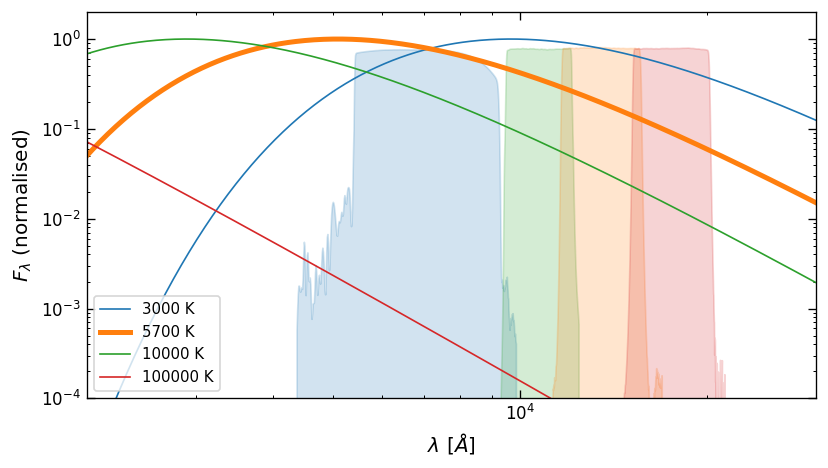

In [11]:
T_bb = 5700 * u.K
bb = BlackBody(T_bb, scale=1.0 * u.erg / (u.cm**2 * u.AA * u.s * u.sr))

def bb_flam(lam_AA, bb_model=bb):
    """
    Compute the black-body SED F_lambda on a wavelength grid.

    Parameters
    ----------
    lam_AA : array_like
        Wavelength grid in Angstrom.
    bb_model : astropy.modeling.physical_models.BlackBody, optional
        The black-body model (default is `bb`, with temperature T_bb).

    Returns
    -------
    numpy.ndarray
        F_lambda in erg / (cm2 A s sr), with arbitrary normalisation.
    """
    return bb_model(np.asarray(lam_AA) * u.AA).value

fig, ax = plt.subplots(figsize=(7, 4), dpi=120, tight_layout=True)
for T in [3000, 5700, 10000, 100000]:
    f = bb_flam(lam_plot.value, BlackBody(T * u.K, scale=1.0 * u.erg / (u.cm**2 * u.AA * u.s * u.sr)))
    ax.plot(lam_plot, f / f.max(), lw=3 if T == T_bb.value else 1, label=f'{T} K')
for (band, filt), col in zip(filters.items(), colors):
    ax.fill_between(filt['lambda'], filt['T'], 0., color=col, alpha=0.2)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(2000, 30000)
ax.set_ylim(1.e-4, 2)
ax.set_xlabel(r'$\lambda\ [\AA]$', fontsize=12)
ax.set_ylabel(r'$F_\lambda$ (normalised)', fontsize=12)
set_ticks(ax)
ax.legend(loc='lower left', fontsize=9)
plt.show()

### Derive the coefficients $C_X$

The integrals are computed on the wavelength grid of each filter. The monochromatic value $k(\lambda_{\rm eff})$ is printed for comparison.

In [12]:
ebv_ref = 0.01   # reference E(B-V) for the integral: C_X is exact at this value (see non-linearity below)

C_X = {}
print(f'SED: black body T = {T_bb}; extinction law: G23 Rv = {RV}\n')
print(f"{'Filter':6s} {'lambda_eff[A]':>14s} {'C_X':>8s} {'k(lambda_eff)':>14s}")
for band, filt in filters.items():
    lam, trans = np.asarray(filt['lambda']), np.asarray(filt['T'])
    C_X[band] = compute_C(lam, trans, bb_flam(lam), ext, ebv_ref=ebv_ref)
    k_eff = ext(leff[band] * u.AA) * RV
    print(f'{band:6s} {leff[band]:14.1f} {C_X[band]:8.3f} {k_eff:14.3f}')

SED: black body T = 5700.0 K; extinction law: G23 Rv = 3.1

Filter  lambda_eff[A]      C_X  k(lambda_eff)
VIS            7334.4    2.248          2.094
Y             10866.2    1.095          1.054
J             13766.7    0.743          0.707
H             17825.2    0.481          0.458


#### Dependence on the SED

A blue SED is more affected by the reddening than a red one in the same filter, the effect being larger for the broad VIS filter. The table shows how much $C_X$ changes with the black body temperature.

In [13]:
temps = [3000, 4000, 5700, 10000, 100000]
rows = []
for T in temps:
    bb_T = BlackBody(T * u.K, scale=1.0 * u.erg / (u.cm**2 * u.AA * u.s * u.sr))
    row = {'T_bb [K]': T}
    for band, filt in filters.items():
        lam, trans = np.asarray(filt['lambda']), np.asarray(filt['T'])
        row[band] = compute_C(lam, trans, bb_flam(lam, bb_T), ext, ebv_ref=ebv_ref)
    rows.append(row)
pd.DataFrame(rows).set_index('T_bb [K]').round(3)

,VIS,Y,J,H
T_bb [K],,,,
3000,2.048,1.076,0.730,0.476
4000,2.150,1.086,0.737,0.479
5700,2.248,1.095,0.743,0.481
10000,2.344,1.102,0.749,0.483
100000,2.434,1.110,0.754,0.486


#### Non-linearity: the reference E(B-V)

E(B-V) enters the definition of $C_X$ in the exponent, inside the integral:
$10^{-0.4\,k(\lambda)\,E(B-V)} = \left(10^{-0.4\,k(\lambda)}\right)^{E(B-V)}$. 
It cannot be factored out, so the integral can only be computed for a given value of E(B-V). 
In `compute_C` this is the parameter `ebv_ref`.

The physical reason is that $k(\lambda)$ is not constant across a broad filter: in VIS it goes 
from about 3.2 on the blue side to about 1.3 on the red side. Dust suppresses the blue part 
of the band more than the red part, so the light transmitted through the filter becomes 
redder as E(B-V) increases, and on this redder light the effective $k$ is smaller. 
As a result $A_X$ grows slightly less than linearly with E(B-V), and $C_X = A_X/E(B-V)$ 
slowly decreases. To first order:

$$C_X(E) \simeq \langle k \rangle_w - 0.46\, E(B-V)\, \sigma^2_{k,w}$$

where the mean and variance of $k(\lambda)$ are weighted by $R_X(\lambda)F(\lambda)$. 
The effect scales with the variance of $k$ within the band: it is largest for the broad 
VIS filter and small for $Y_E$, $J_E$, $H_E$.

Consequences:
* Even if the SED were perfectly known, a single coefficient $C_X$ is exact only at the 
  E(B-V) where it was computed. Here we use a small `ebv_ref` (0.01), i.e. the slope of 
  $A_X(E)$ at the origin, appropriate for the low E(B-V) of the Euclid fields.
* Computing $C_X$ at a large reference value (e.g. E(B-V) = 1) and then applying it as 
  $C_X \times E(B-V)$ to low-extinction fields would introduce an error of a few percent 
  in VIS.
* To be exact for the assumed SED, $C_X$ can be computed at the E(B-V) of each object, by 
  interpolating the grid computed below (set `use_ebv_dependent_C = True` in Section 4).
* For the Euclid fields (E(B-V) ≲ 0.1) the effect is about 0.001 mag, much smaller than 
  the uncertainty due to the choice of the SED.
* Spectra are not affected: the correction $10^{0.4\,k(\lambda)\,E(B-V)}$ is applied pixel 
  by pixel and is exact for any E(B-V).

#### Illustration

The function below shows the mechanism with the ingredients defined above (filter, black body SED, G23).

* **Left:** the light transmitted through the filter, $R_X(\lambda)F(\lambda)$, without dust (grey dashed) and with dust (solid orange), both normalised to the peak without dust: the grey shaded area is the light absorbed by the dust. The dotted orange curve is the light with dust rescaled to its own peak, to compare the shapes. The purple curve is $k(\lambda)$. The vertical lines mark the mean wavelength of the transmitted light: with dust it moves redward, where $k$ is smaller.
* **Right:** $A_X$ as a function of E(B-V). The dashed line is the linear approximation $C_X(E\to0)\times E(B-V)$, the solid curve is the exact integral for the same SED. The vertical segment is the error of the linear approximation at the chosen E(B-V).

The range of E(B-V) (up to 2) is deliberately much larger than in the Euclid fields, so that the effect is visible.

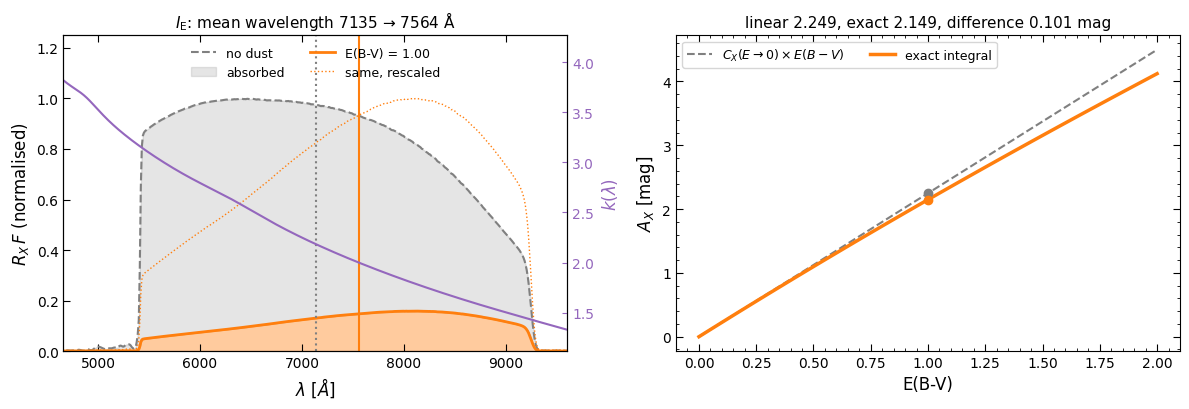

In [14]:
def plot_nonlinearity(ebv=1.0, band='VIS', ebv_max=2.0):
    """
    Illustrate the non-linearity of the broad-band extinction for one filter.

    Left panel: light transmitted through the filter with and without dust,
    and k(lambda). Right panel: A_X as a function of E(B-V), exact integral
    versus the linear approximation C_X(E->0) * E(B-V).
    It uses the filters (`filters`), the extinction law (`ext`, `RV`) and the
    black-body SED (`bb_flam`) defined above.

    Parameters
    ----------
    ebv : float, optional
        E(B-V) to display (default is 1.0).
    band : str, optional
        Filter name, a key of `filters`: 'VIS', 'Y', 'J' or 'H' (default is 'VIS').
    ebv_max : float, optional
        Maximum E(B-V) of the right panel (default is 2.0).

    Returns
    -------
    None
    """
    lam = np.asarray(filters[band]['lambda'], dtype=float)
    trans = np.asarray(filters[band]['T'], dtype=float)
    ebv = max(float(ebv), 1.e-4)                  # avoid E(B-V) = 0 in compute_C
    
    w0 = trans * lam * bb_flam(lam)               # R_X * F without dust
    w = w0 * ext.extinguish(lam * u.AA, Ebv=ebv)  # R_X * F with dust
    lam_0 = np.trapezoid(w0 * lam, lam) / np.trapezoid(w0, lam)
    lam_e = np.trapezoid(w * lam, lam) / np.trapezoid(w, lam)

    C0 = compute_C(lam, trans, bb_flam(lam), ext, ebv_ref=1.e-4)
    e_grid = np.linspace(1.e-4, ebv_max, 41)
    A_true = np.array([compute_C(lam, trans, bb_flam(lam), ext, ebv_ref=e) * e for e in e_grid])
    A_true_ebv = compute_C(lam, trans, bb_flam(lam), ext, ebv_ref=ebv) * ebv
    A_lin_ebv = C0 * ebv

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), dpi=100, tight_layout=True)

    # left: transmitted light
    norm = w0.max()
    ax1.plot(lam, w0 / norm, color='grey', ls='--', lw=1.5, label='no dust')
    ax1.fill_between(lam, w / norm, w0 / norm, color='grey', alpha=0.2, label='absorbed')
    ax1.fill_between(lam, w / norm, 0., color='tab:orange', alpha=0.4)
    ax1.plot(lam, w / norm, color='tab:orange', lw=2, label=f'E(B-V) = {ebv:.2f}')
    ax1.plot(lam, w / w.max(), color='tab:orange', lw=1, ls=':', label='same, rescaled')
    ax1.axvline(lam_0, color='grey', ls=':', lw=1.5)
    ax1.axvline(lam_e, color='tab:orange', lw=1.5)
    ax1.set_xlabel(r'$\lambda\ [\AA]$', fontsize=12)
    ax1.set_ylabel(r'$R_X\,F$ (normalised)', fontsize=12)
    inband = lam[trans > 0.01 * trans.max()]
    ax1.set_xlim(inband.min() - 300, inband.max() + 300)
    ax1.set_ylim(0, 1.25)
    ax1.set_title(f'{euclid_filters[band][1]}: mean wavelength {lam_0:.0f} → {lam_e:.0f} Å', fontsize=11)
    ax1.legend(loc='upper center', fontsize=9, ncol=2, frameon=False)
    set_ticks(ax1)
    ax1k = ax1.twinx()
    ax1k.plot(lam, ext(lam * u.AA) * RV, color='tab:purple', lw=1.5)
    ax1k.set_ylabel(r'$k(\lambda)$', color='tab:purple', fontsize=12)
    ax1k.tick_params(axis='y', colors='tab:purple', direction='in')

    # right: A_X vs E(B-V)
    ax2.plot(e_grid, C0 * e_grid, color='grey', ls='--', lw=1.5, label=r'$C_X(E\to0)\times E(B-V)$')
    ax2.plot(e_grid, A_true, color='tab:orange', lw=2.5, label='exact integral')
    ax2.plot([ebv, ebv], [A_true_ebv, A_lin_ebv], color='tab:purple', lw=2.5)
    ax2.plot(ebv, A_lin_ebv, 'o', color='grey')
    ax2.plot(ebv, A_true_ebv, 'o', color='tab:orange')
    ax2.set_xlabel('E(B-V)', fontsize=12)
    ax2.set_ylabel(r'$A_X$ [mag]', fontsize=12)
    ax2.set_title(f'linear {A_lin_ebv:.3f}, exact {A_true_ebv:.3f}, '
                  f'difference {A_lin_ebv - A_true_ebv:.3f} mag', fontsize=11)
    ax2.xaxis.set_minor_locator(AutoMinorLocator(5))
    ax2.yaxis.set_minor_locator(AutoMinorLocator(5))
    ax2.legend(loc='upper left', fontsize=9, ncol=2)
    set_ticks(ax2)
    plt.show()

# static version (visible also when the notebook is exported or viewed offline)
plot_nonlinearity(ebv=1.0, band='VIS')

Interactive version: move the slider to change E(B-V) and choose the filter. It requires `ipywidgets`; if it is not available the static plot above is enough. Try E(B-V) ≈ 0.05, typical of the Euclid fields: the difference becomes negligible.

In [15]:
try:
    from ipywidgets import interact, FloatSlider, Dropdown
    interact(plot_nonlinearity,
             ebv=FloatSlider(min=0., max=2., step=0.05, value=1.0, description='E(B-V)', continuous_update=False),
             band=Dropdown(options=list(filters), value='VIS', description='Filter'),
             ebv_max=2.0)
except ImportError:
    print('⚠️ ipywidgets is not available: use plot_nonlinearity(ebv, band) to change the values')

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='E(B-V)', max=2.0, step=0.05…

#### $C_X$ as a function of E(B-V)

The grid below is used when `use_ebv_dependent_C = True` in Section 4. The plot shows $C_X(E(B-V))$ normalised to its value for E(B-V) → 0.

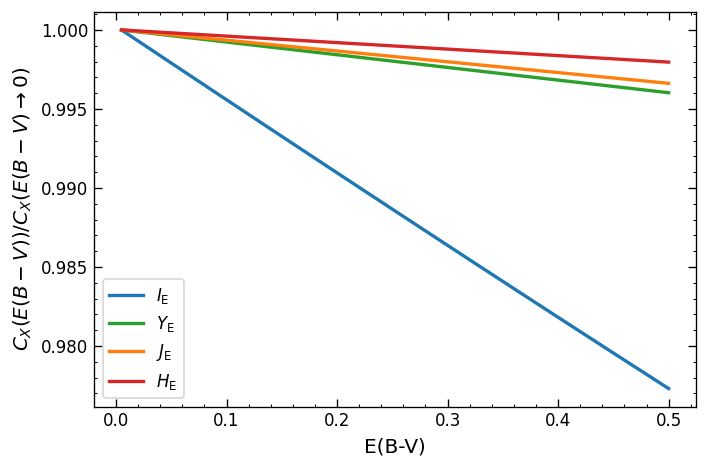

In [16]:
ebv_grid = np.linspace(0.005, 0.5, 40)
C_grid = {band: np.array([compute_C(np.asarray(f['lambda']), np.asarray(f['T']), 
                                    bb_flam(np.asarray(f['lambda'])), ext, ebv_ref=e) 
                          for e in ebv_grid]) 
          for band, f in filters.items()}

fig, ax = plt.subplots(figsize=(6, 4), dpi=120, tight_layout=True)
for (band, C), col in zip(C_grid.items(), colors):
    ax.plot(ebv_grid, C / C[0], color=col, lw=2, label=euclid_filters[band][1])
ax.set_xlabel('E(B-V)', fontsize=12)
ax.set_ylabel(r'$C_X(E(B-V)) / C_X(E(B-V)\to 0)$', fontsize=12)
ax.xaxis.set_minor_locator(AutoMinorLocator(5))
ax.yaxis.set_minor_locator(AutoMinorLocator(5))
set_ticks(ax)
ax.legend()
plt.show()

#### Save the coefficients

In [17]:
fileout = output_folder + f'MW_correction_factors_Euclid_BB{int(T_bb.value)}_G23.txt'
with open(fileout, 'w') as f:
    f.write('# MW attenuation correction factors: m_intrinsic = m_observed - C * EBV\n')
    f.write('#                                    F_intrinsic = F_observed * 10**(0.4 * C * EBV)\n')
    f.write(f'# Extinction curve G23 (Gordon et al. 2023) Rv={RV} ; SED black body T={T_bb.value:.0f} K\n')
    f.write('# Filter   lambda_eff[A]      C\n')
    for band in filters:
        f.write(f'{band:8s} {leff[band]:12.1f} {C_X[band]:8.3f}\n')
print(open(fileout).read())
print(f'✅ Saved to {fileout}')

# MW attenuation correction factors: m_intrinsic = m_observed - C * EBV
#                                    F_intrinsic = F_observed * 10**(0.4 * C * EBV)
# Extinction curve G23 (Gordon et al. 2023) Rv=3.1 ; SED black body T=5700 K
# Filter   lambda_eff[A]      C
VIS            7334.4    2.248
Y             10866.2    1.095
J             13766.7    0.743
H             17825.2    0.481

✅ Saved to /media/user/example_notebook_outputs/MW_correction_factors_Euclid_BB5700_G23.txt


## 3. Query the photometric catalogue (MER)

The photometric (MER) catalogue contains, besides fluxes and shapes of the detected objects, the E(B-V) value at the position of each object in the column `gal_ebv`. 

In this example we select the objects in a tile of the EDF-N, the Euclid Deep Field North. 
The catalogue to use is chosen with the variable `survey` in the cell "Tables used in the queries" (`'deep'` or `'wide'`). The catalogues are divided into tiles, i.e. the sky areas in which they are produced: their index starts with 101 in the Deep Fields and 102 in the Wide Survey. If you change `survey`, also change `tile_index` below (and `obj_id` in Section 5) to a tile and an object of the same survey.

The fluxes are in $\mu$Jy. Here the Sérsic fluxes are used as an example, but any flux column can be corrected in the same way (just modify the `euclid_filters` dictionary in Section 1 accordingly). Check the list of available columns with the cells in Appendix A.

To limit the number of output objects you can select a random sample with 

```sql
       AND RAND() < 0.1
```
or have a deterministic 10% sampling with

```sql
       AND MOD(mer.object_id, 10) = 0
```

In [18]:
tile_index = 101834632   # tiles starting with 101 are for the deep, 102 are for the wide

In [19]:
flux_cols = ', '.join([f'mer.{v[2]}, mer.{v[3]}' for v in euclid_filters.values()])

query = f"""SELECT mer.object_id, mer.right_ascension, mer.declination, mer.tile_index,
            mer.gal_ebv, mer.vis_det, mer.point_like_prob,
            {flux_cols}
            FROM {table_mer} AS mer
            WHERE mer.tile_index = {tile_index}
            AND mer.spurious_flag = 0"""
print(query)

SELECT mer.object_id, mer.right_ascension, mer.declination, mer.tile_index,
            mer.gal_ebv, mer.vis_det, mer.point_like_prob,
            mer.flux_vis_sersic, mer.fluxerr_vis_sersic, mer.flux_y_sersic, mer.fluxerr_y_sersic, mer.flux_j_sersic, mer.fluxerr_j_sersic, mer.flux_h_sersic, mer.fluxerr_h_sersic
            FROM dr1.mer_catalogue_deep_survey AS mer
            WHERE mer.tile_index = 101834632
            AND mer.spurious_flag = 0


In [20]:
%%time
ymd_hms_query = datetime.datetime.now(datetime.timezone(datetime.timedelta(hours=1))).strftime('%y%m%d-%H%M%S')
mer_table = get_query_results(query, name='MER-EBV-query-result_' + ymd_hms_query, n_rows=3, **QUERY_OPTIONS)

INFO: Query finished. [astroquery.utils.tap.core]
* Output table contains 45,273 rows
* Total runtime: 2.4 seconds
* Displaying first 3 rows: 


object_id,right_ascension,declination,tile_index,gal_ebv,vis_det,point_like_prob,flux_vis_sersic,fluxerr_vis_sersic,flux_y_sersic,fluxerr_y_sersic,flux_j_sersic,fluxerr_j_sersic,flux_h_sersic,fluxerr_h_sersic
NA,deg,deg,,mag,NA,NA,uJy,uJy,uJy,uJy,uJy,uJy,uJy,uJy
int64,float64,float64,int64,float64,int16,float64,float64,float64,float64,float64,float64,float64,float64,float64
2696214630661275751,269.621463040781,66.12757511678392,101834632,0.05757847800850868,1,5.715921724913642e-05,0.40388593077659607,0.00588161451742053,0.8184272646903992,0.025617901235818863,1.4476001262664795,0.033510737121105194,1.636553168296814,0.0363018624484539
2700048964661283093,270.0048964044859,66.12830939397264,101834632,0.05345594510436058,1,--,0.06249690428376198,0.004100981634110212,0.2025238275527954,0.0743565782904625,0.311093270778656,0.11144549399614334,0.4081561267375946,0.14436757564544678
2699356418661242231,269.93564186698325,66.12422316176021,101834632,0.05462705343961716,1,0.9853345155715942,29.34996223449707,0.1317044049501419,106.73149871826172,0.660415530204773,124.05242156982422,0.6692829132080078,126.76545715332031,0.592573344707489


CPU times: user 1.03 s, sys: 13.6 ms, total: 1.05 s
Wall time: 2.35 s


In [21]:
# output_file = 'example_mer_ebv.fits'
output_file = 'example_mer_ebv.parquet'
mer_table.write(output_folder + output_file, overwrite=True)
print(f'✅ Saved to {output_folder + output_file}')

✅ Saved to /media/user/example_notebook_outputs/example_mer_ebv.parquet


Or read the existing file

In [22]:
# file = 'example_mer_ebv.fits'
file = 'example_mer_ebv.parquet'
mer_table = Table.read(output_folder + file)
print(f'Loaded {len(mer_table)} rows and {len(mer_table.colnames)} columns')

Loaded 45273 rows and 15 columns


### E(B-V) in the selected area

E(B-V): min = 0.0523  median = 0.0584  max = 0.0642


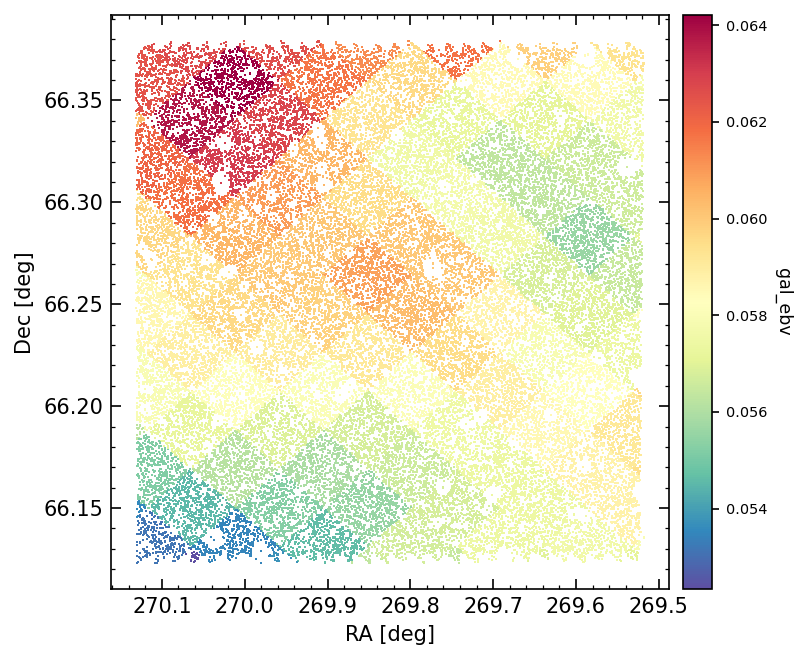

In [23]:
ebv_values = np.ma.filled(np.ma.masked_array(mer_table['gal_ebv'], dtype=float), np.nan)   # masked values -> NaN
print(f"E(B-V): min = {np.nanmin(ebv_values):.4f}  "
      f"median = {np.nanmedian(ebv_values):.4f}  "
      f"max = {np.nanmax(ebv_values):.4f}")

fig, ax = plt.subplots(figsize=(5.5, 4.5), dpi=150, tight_layout=True)
sc = ax.scatter(mer_table['right_ascension'], mer_table['declination'], s=1, marker='s',
                c=mer_table['gal_ebv'], cmap=plt.cm.Spectral_r, edgecolors='None')
cbar = plt.colorbar(sc, pad=0.02)
cbar.set_label('gal_ebv', size='small', rotation=270, labelpad=12)
cbar.ax.tick_params(labelsize='x-small')
ax.invert_xaxis()
ax.xaxis.set_minor_locator(AutoMinorLocator(5))
ax.yaxis.set_minor_locator(AutoMinorLocator(5))
set_ticks(ax)
ax.set_xlabel('RA [deg]')
ax.set_ylabel('Dec [deg]')
plt.show()

## 4. Correct the fluxes for the MW attenuation

For each band $X$:

$$A_X = C_X \times E(B-V), \qquad F_{X,i} = F_{X,o}\times 10^{0.4\, A_X}, \qquad \sigma_{F_{X,i}} = \sigma_{F_{X,o}}\times 10^{0.4\, A_X}$$

The uncertainty on E(B-V) is not propagated. The new columns have the suffix `_mwcorr`, and the attenuation in each band is stored in the columns `A_<band>`.

In [24]:
use_ebv_dependent_C = False   # True: interpolate C_X(E(B-V)) computed above

def correct_fluxes(tab, filter_dict, C_dict, ebv_col='gal_ebv', C_grid=None, ebv_grid=None):
    """
    Correct the fluxes of a catalogue for the MW attenuation.

    For each band X: A_X = C_X * E(B-V), F_corr = F_obs * 10^(0.4 A_X), and the
    same factor is applied to the flux errors (the error on E(B-V) is not
    propagated). New columns: A_<band>, <flux_col>_mwcorr, <fluxerr_col>_mwcorr.

    Parameters
    ----------
    tab : astropy.table.Table
        Catalogue with the flux columns and the E(B-V) column.
    filter_dict : dict
        {band: (svo_id, label, flux_col, fluxerr_col)}, e.g. `euclid_filters`.
    C_dict : dict
        {band: C_X}, the coefficients computed in Section 2.
    ebv_col : str, optional
        Name of the E(B-V) column (default is 'gal_ebv').
    C_grid : dict, optional
        {band: array of C_X computed on `ebv_grid`}. If given, C_X is
        interpolated at the E(B-V) of each object instead of using `C_dict`
        (default is None).
    ebv_grid : numpy.ndarray, optional
        E(B-V) values of `C_grid` (default is None).

    Returns
    -------
    astropy.table.Table
        A copy of the input catalogue, with the new columns.
    """
    tab = tab.copy()
    ebv = np.asarray(tab[ebv_col], dtype=float)
    for band, (_, _, fcol, ecol) in filter_dict.items():
        if C_grid is not None:
            C = np.interp(ebv, ebv_grid, C_grid[band])
        else:
            C = C_dict[band]
        A = C * ebv
        factor = 10**(0.4 * A)
        tab[f'A_{band}'] = A
        tab[f'{fcol}_mwcorr'] = tab[fcol] * factor
        tab[f'{ecol}_mwcorr'] = tab[ecol] * factor
        for col in [f'{fcol}_mwcorr', f'{ecol}_mwcorr']:
            tab[col].unit = tab[fcol].unit
    return tab

if use_ebv_dependent_C:
    mer_corr = correct_fluxes(mer_table, euclid_filters, C_X, C_grid=C_grid, ebv_grid=ebv_grid)
else:
    mer_corr = correct_fluxes(mer_table, euclid_filters, C_X)

show_cols = ['object_id', 'gal_ebv'] + [c for b, v in euclid_filters.items() 
                                        for c in (v[2], v[2] + '_mwcorr', f'A_{b}')]
mer_corr[show_cols][0:5]

object_id,gal_ebv,flux_vis_sersic,flux_vis_sersic_mwcorr,A_VIS,flux_y_sersic,flux_y_sersic_mwcorr,A_Y,flux_j_sersic,flux_j_sersic_mwcorr,A_J,flux_h_sersic,flux_h_sersic_mwcorr,A_H
NA,mag,uJy,uJy,,uJy,uJy,,uJy,uJy,,uJy,uJy,
int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
2696214630661275751,0.05757847800850868,0.40388593077659607,0.4550285508037614,0.12944980603997025,0.8184272646903992,0.8673377922759193,0.06302045344361318,1.4476001262664795,1.5058020866422488,0.042798205761606124,1.636553168296814,1.6788472898770528,0.027702686813059228
2700048964661283093,0.05345594510436058,0.06249690428376198,0.06981215801188481,0.12018139354812729,0.2025238275527954,0.2137368674014668,0.0585082832379812,0.311093270778656,0.3226890171996623,0.03973391824319258,0.4081561267375946,0.417940065389435,0.02571921587269728
2699356418661242231,0.05462705343961716,29.34996223449707,32.86497253765812,0.12281431737824927,106.73149871826172,112.77391019194177,0.059790077770802266,124.05242156982422,128.77958125274645,0.04060440557170508,126.76545715332031,129.8715414052268,0.026282670284100477
2697901192661325148,0.056702446192502975,0.17154301702976227,0.19291462680441257,0.1274802828328785,0.1728104054927826,0.18297617258689985,0.06206162430840135,0.23858016729354858,0.24802368661808954,0.042147049440496256,0.302384614944458,0.3100788693647784,0.027281202330029033
2695432981661363475,0.05874021723866463,0.07576028257608414,0.08555910880180245,0.13206166594343086,0.19967055320739746,0.2118511464365831,0.06429199335921919,0.11288978904485703,0.11752204854098583,0.04366172901427349,0.1718452423810959,0.1763770873042531,0.02826163347446106


Add also the AB magnitudes, observed and corrected:

In [25]:
for band, (_, _, fcol, _) in euclid_filters.items():
    mer_corr[f'mag_{band}'] = flux_to_mag(mer_corr[fcol])
    mer_corr[f'mag_{band}_mwcorr'] = flux_to_mag(mer_corr[f'{fcol}_mwcorr'])

# check: m_corr - m_obs = -A_X
band = 'VIS'
diff = mer_corr[f'mag_{band}_mwcorr'] - mer_corr[f'mag_{band}'] + mer_corr[f'A_{band}']
print(f'Max |m_corr - m_obs + A_{band}| = {np.nanmax(np.abs(diff)):.2e}')

Max |m_corr - m_obs + A_VIS| = 4.66e-15


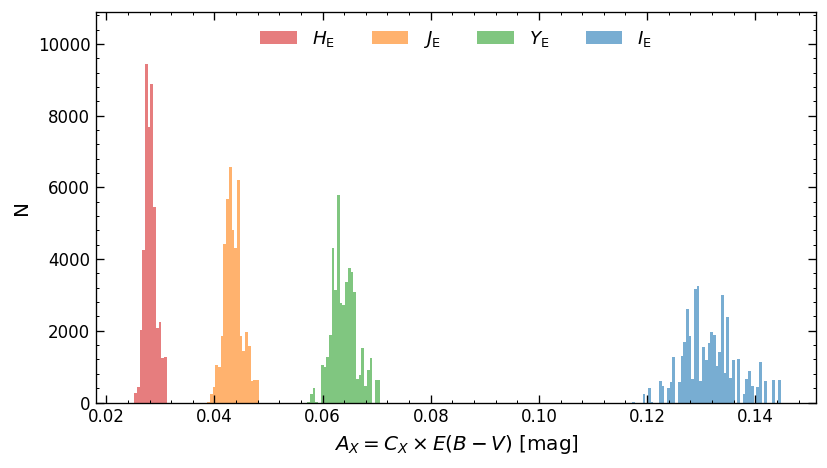

In [26]:
fig, ax = plt.subplots(figsize=(7, 4), dpi=120, tight_layout=True)

dm = 0.0005
A_all = np.concatenate([np.asarray(mer_corr[f'A_{b}'], dtype=float) for b in euclid_filters])
bins = np.arange(np.nanmin(A_all) - 2*dm, np.nanmax(A_all) + 2*dm, dm)   # same bins for all bands

for (band, label), col in zip([(b, v[1]) for b, v in euclid_filters.items()], colors):
    ax.hist(mer_corr[f'A_{band}'], bins=bins, color=col, alpha=0.6, label=label,
             linewidth=1.2)

ax.set_xlabel(r'$A_X = C_X \times E(B-V)$ [mag]', fontsize=12)
ax.set_ylabel('N', fontsize=12)
ax.set_ylim(top=ax.get_ylim()[1] * 1.10)
ax.xaxis.set_minor_locator(AutoMinorLocator(5))
ax.yaxis.set_minor_locator(AutoMinorLocator(5))
set_ticks(ax)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc='upper center', ncol=4, frameon=False, fontsize=11)
plt.show()

In [27]:
# output_file = 'example_mer_ebv_mwcorr.fits'
output_file = 'example_mer_ebv_mwcorr.parquet'
mer_corr.write(output_folder + output_file, overwrite=True)
print(f'✅ Saved to {output_folder + output_file}')

✅ Saved to /media/user/example_notebook_outputs/example_mer_ebv_mwcorr.parquet


## 5. Retrieve a spectrum and correct it for the MW attenuation

The table `table_source` (`dr1.spectra_source`) gives the path of the files containing the 1D spectra of the selected objects, combined from all the available exposures. There is one row per grism: BGS for the blue and RGS for the red grism. The photometric (MER) catalogue is joined to retrieve `gal_ebv`, and the spectroscopic-redshift (SPE) catalogue to retrieve the redshift of the most probable solution (`spe_rank = 0`).

For a spectrum the correction is monochromatic, i.e. it is applied pixel by pixel. Each spectrum has, among others, the columns `SIGNAL` (the flux) and `VAR` (its variance, so that the 1σ error is $\sqrt{\rm VAR}$). The flux is divided by the attenuation and, consequently, the error by the same factor and the variance by its square:

$$F_i(\lambda) = F_o(\lambda) / 10^{-0.4\, k(\lambda)\, E(B-V)}, \qquad {\rm VAR}_i(\lambda) = {\rm VAR}_o(\lambda) / \left(10^{-0.4\, k(\lambda)\, E(B-V)}\right)^2$$

where $10^{-0.4\, k(\lambda)\, E(B-V)}$ is given by `ext.extinguish(wave, Ebv=EBV)`. The corrected values are stored in the new columns `SIGNAL_MWCORR` and `VAR_MWCORR`. As for the photometry, the uncertainty on E(B-V) is not propagated.

In [28]:
obj_id = 2700053415663577514  # change this to the source you are interested in

In [29]:
query = f"""SELECT spec.source_id, spec.ra_obj, spec.dec_obj, 
            spec.datalabs_path, spec.file_name, spec.hdu_index, spec.dith_num,
            mer.tile_index, mer.gal_ebv,
            spe.spe_z, spe.spe_z_err, spe.spe_z_prob, spe.spe_rank, spe.spe_z_rel, 
            speq.spe_npix, speq.spe_n_dith_med,
            combined.lambda_range
            FROM {table_source} AS spec
            JOIN {table_mer} AS mer
              ON spec.source_id = mer.object_id
            JOIN {table_spe} AS spe
              ON spec.source_id = spe.object_id
              AND spe.spe_rank = 0
            JOIN {table_qual} AS speq
              ON spec.source_id = speq.object_id
            JOIN {table_comb} AS combined
              ON spec.combined_spectra_fk = combined.combined_spectra_oid
            WHERE mer.object_id = {obj_id}"""

In [30]:
ymd_hms_query = datetime.datetime.now(datetime.timezone(datetime.timedelta(hours=1))).strftime('%y%m%d-%H%M%S')
spec_info = get_query_results(query, name='Spectra-query-result_' + ymd_hms_query, n_rows=2, **QUERY_OPTIONS)

INFO: Query finished. [astroquery.utils.tap.core]
* Output table contains 2 rows
* Total runtime: 0.9 seconds
* Displaying first 2 rows: 


source_id,ra_obj,dec_obj,datalabs_path,file_name,hdu_index,dith_num,tile_index,gal_ebv,spe_z,spe_z_err,spe_z_prob,spe_rank,spe_z_rel,spe_npix,spe_n_dith_med,lambda_range
,,,,,,,,mag,NA,NA,NA,NA,NA,NA,,
int64,float64,float64,object,object,int64,int64,int64,float64,float64,float64,float64,int16,float64,int16,int16,object
2700053415663577514,270.005341527258,66.3577514966446,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/101834632,EUC_SIR_W-COMBSPEC_101834632_20250907T185631.914464Z.fits,3615,11,101834632,0.06420887261629105,0.8490099310874939,0.00018429230840411037,0.9999618530273438,0,0.4270864427089691,849,23,BGS
2700053415663577514,270.005341527258,66.3577514966446,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/101834632,EUC_SIR_W-COMBSPEC_101834632_20250908T033801.776405Z.fits,8811,35,101834632,0.06420887261629105,0.8490099310874939,0.00018429230840411037,0.9999618530273438,0,0.4270864427089691,849,23,RGS


### Read and save the spectrum

In [31]:
spectra = {}   # grism : astropy Table with WAVELENGTH, SIGNAL, MASK, QUALITY, VAR, NDITH
file_source_id = str(obj_id)

for row in spec_info:
    grism = str(row['lambda_range']).strip().upper()
    fits_file_path = row['datalabs_path'] + '/' + row['file_name']
    hdu = row['hdu_index']
    print(f'===== {grism} =====')
    print(f'* Reading HDU {hdu} of {fits_file_path}')
    with fits.open(fits_file_path, memmap=True) as hdul:
        spec_hdu = hdul[hdu].copy()
    spectra[grism] = Table(spec_hdu.data)
    for col in spectra[grism].colnames:   # keep the units from the header
        spectra[grism][col].unit = spec_hdu.columns[col].unit
    output_file = output_folder + f'{file_source_id}_{grism}.fits'
    spec_hdu.writeto(output_file, overwrite=True)
    print(f'* Columns: {spectra[grism].colnames}')
    print(f'* Saved to {output_file}\n')

===== BGS =====
* Reading HDU 3615 of /data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/101834632/EUC_SIR_W-COMBSPEC_101834632_20250907T185631.914464Z.fits
* Columns: ['WAVELENGTH', 'SIGNAL', 'MASK', 'QUALITY', 'VAR', 'NDITH']
* Saved to /media/user/example_notebook_outputs/2700053415663577514_BGS.fits

===== RGS =====
* Reading HDU 8811 of /data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/101834632/EUC_SIR_W-COMBSPEC_101834632_20250908T033801.776405Z.fits
* Columns: ['WAVELENGTH', 'SIGNAL', 'MASK', 'QUALITY', 'VAR', 'NDITH']
* Saved to /media/user/example_notebook_outputs/2700053415663577514_RGS.fits



### Correct the spectrum

In [32]:
EBV = float(spec_info['gal_ebv'][0])
z_spe = float(spec_info['spe_z'][0])
print(f'object_id = {obj_id}   E(B-V) = {EBV:.4f}   z_spe = {z_spe:.4f}')

for grism, spec in spectra.items():
    wave = np.asarray(spec['WAVELENGTH'], dtype=float) * u.AA   # check the unit in the header
    att = ext.extinguish(wave, Ebv=EBV)                          # 10^(-0.4 k(lambda) EBV)
    spec['SIGNAL_MWCORR'] = spec['SIGNAL'] / att
    spec['VAR_MWCORR'] = spec['VAR'] / att**2
    spec['SIGNAL_MWCORR'].unit = spec['SIGNAL'].unit
    spec['VAR_MWCORR'].unit = spec['VAR'].unit
    print(f'{grism}: correction factor from {1/att.max():.4f} to {1/att.min():.4f}')

object_id = 2700053415663577514   E(B-V) = 0.0642   z_spe = 0.8490
BGS: correction factor from 1.0422 to 1.1020
RGS: correction factor from 1.0246 to 1.0549


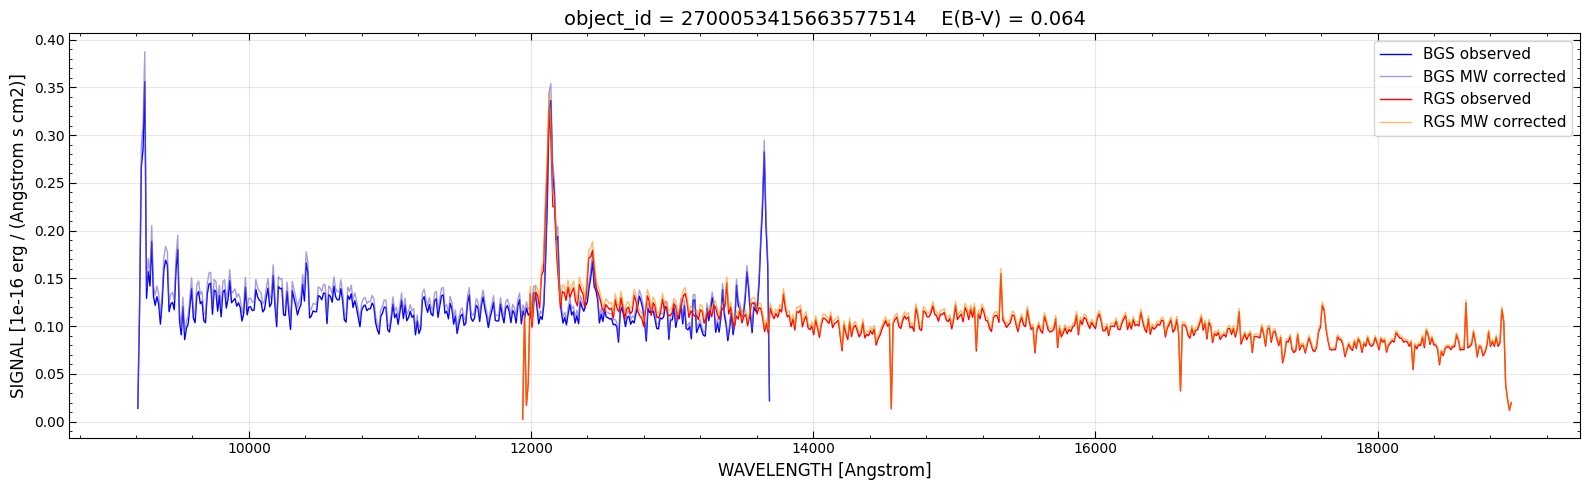

In [33]:
grism_color  = {'BGS': 'blue', 'RGS': 'red'}
grism_color2 = {'BGS': 'SlateBlue', 'RGS': 'DarkOrange'}

fig, ax = plt.subplots(figsize=(16, 5), dpi=100, tight_layout=True)
for grism, spec in spectra.items():
    good = spec['VAR'] > 0     # skip pixels without data
    ax.plot(spec['WAVELENGTH'][good], spec['SIGNAL'][good], lw=1, 
            color=grism_color.get(grism), label=f'{grism} observed')
    ax.plot(spec['WAVELENGTH'][good], spec['SIGNAL_MWCORR'][good], lw=1, alpha=0.6,
            color=grism_color2.get(grism), label=f'{grism} MW corrected')

unit_w = spectra[list(spectra)[0]]['WAVELENGTH'].unit
unit_f = spectra[list(spectra)[0]]['SIGNAL'].unit
ax.set_title(f'object_id = {obj_id}    E(B-V) = {EBV:.3f}', fontsize=14)
ax.set_xlabel(f'WAVELENGTH [{unit_w}]', fontsize=12)
ax.set_ylabel(f'SIGNAL [{unit_f}]', fontsize=12)
ax.xaxis.set_minor_locator(AutoMinorLocator(5))
ax.yaxis.set_minor_locator(AutoMinorLocator(5))
set_ticks(ax)
ax.grid(alpha=0.3)
ax.legend(fontsize=11)
plt.show()

### Save the corrected spectrum

In [34]:
for grism, spec in spectra.items():
    output_file = output_folder + f'{file_source_id}_{grism}_mwcorr.fits'
    spec.meta['OBJ_ID'] = obj_id
    spec.meta['GAL_EBV'] = (EBV, 'E(B-V) used for the MW correction')
    spec.meta['EXTLAW'] = (f'G23 Rv={RV}', 'MW extinction law')
    spec.write(output_file, overwrite=True)
    print(f'✅ Saved to {output_file}')

✅ Saved to /media/user/example_notebook_outputs/2700053415663577514_BGS_mwcorr.fits
✅ Saved to /media/user/example_notebook_outputs/2700053415663577514_RGS_mwcorr.fits


# Appendix A: Retrieve info on tables

The cells below list the columns of the tables used in the notebook, with their units and descriptions. They use the login done at the beginning.

In [35]:
# list the MER columns related to extinction and all the flux columns
table = call_with_relogin(Euclid.load_table, table=table_mer, verbose=False, **QUERY_OPTIONS)
for column in table.columns:
    if 'ebv' in column.name or 'flux_' in column.name:
        print(f'{column.name:30s} {str(column.unit):10s} {column.description}')

flux_detection_total           uJy        VIS or NIR stack band source total flux error (Kron aperture)
flux_g_ext_decam_1fwhm_aper    None       None
flux_g_ext_decam_2fwhm_aper    None       None
flux_g_ext_decam_3fwhm_aper    None       None
flux_g_ext_decam_4fwhm_aper    None       None
flux_g_ext_decam_disk_sersic   uJy        Gext DECam band source flux from the Disk+Sersic fit
flux_g_ext_decam_sersic        uJy        Gext DECam band source flux from the Sersic fit
flux_g_ext_decam_templfit      uJy        Gext DECam band source template fitting flux (TPHOT measurement)
flux_g_ext_hsc_1fwhm_aper      None       None
flux_g_ext_hsc_2fwhm_aper      None       None
flux_g_ext_hsc_3fwhm_aper      None       None
flux_g_ext_hsc_4fwhm_aper      None       None
flux_g_ext_hsc_disk_sersic     uJy        Gext HSC band source flux from the Disk+Sersic fit
flux_g_ext_hsc_sersic          uJy        Gext HSC band source flux from the Sersic fit
flux_g_ext_hsc_templfit        uJy        Gext 

In [36]:
# columns of the table with the location of the spectra
table = call_with_relogin(Euclid.load_table, table=table_source, verbose=False, **QUERY_OPTIONS)
for column in table.columns:
    print(column.name)

calblock_id_list
combined_spectra_fk
combined_spectra_product_fk
datalabs_path
dec_obj
dith_num
file_name
file_path
hdu_index
lambda_range
patch_id_list
ra_obj
source_id
sourcepatch_id
spectra_source_oid
to_be_published
